# Parte 2 — Experimentos de busca linear

**Autor:** Tiago. **Disciplina:** Programação Não Linear — UFC.

Executamos **27 casos obrigatórios independentes**: TP 1, TP 8 e TP 15 × gradiente negativo (G), Newton clássico (N) e Newton modificado (M) × Fibonacci, interpolação quadrática/cúbica e Goldstein. Cada caso começa no ponto inicial do enunciado e produz **um passo**, não uma otimização até convergir.

Quando Newton clássico falha na condição de descida, seu diagnóstico é preservado e a direção regularizada é aplicada, conforme o enunciado. Não há três trajetórias distintas quando N e M coincidem.

**Manual:** use Python 3 com NumPy, Matplotlib e Jupyter. Se necessário: `%pip install numpy matplotlib notebook`. Abra este notebook e use *Restart Kernel and Run All Cells*. Não é necessário executar a Parte 1. Pela pasta do notebook ou raiz do repositório, os resultados vão para `resultados/parte2`. As saídas anteriores dessa pasta são atualizadas a cada execução.

As seções abaixo definem as fórmulas e parâmetros, verificam derivadas e rotinas, executam os casos e exportam CSV, JSON e figuras. Os testes extras são guardados separadamente. Os erros identificados e suas correções estão em `auditoria critica de erros.md` e no apêndice do relatório.

In [1]:
from pathlib import Path
import csv
import json
import platform
import importlib.metadata
import html

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, HTML

pastas = [Path.cwd(), Path.cwd() / "programacao nao linear" / "trabalho 1"]
PASTA_TRABALHO = next((p for p in pastas if (p / "parte 2.ipynb").is_file()), None)
if PASTA_TRABALHO is None:
    raise FileNotFoundError("Execute pela pasta do notebook ou pela raiz do repositório.")
PASTA_SAIDA = PASTA_TRABALHO / "resultados" / "parte2"
PASTA_SAIDA.mkdir(parents=True, exist_ok=True)
PARAMETROS = {
    "tolerancia_intervalo": 1e-7, "tolerancia_descida": 1e-12,
    "regularizacao_relativa": 1e-2, "regularizacao_absoluta": 1e-6,
    "passo_inicial": 1.0,
    "max_bracketing": 80, "max_interpolacao": 300,
    "max_goldstein": 100, "c_goldstein": 0.1,
}
print(json.dumps(PARAMETROS, indent=2))

{
  "tolerancia_intervalo": 1e-07,
  "tolerancia_descida": 1e-12,
  "regularizacao_relativa": 0.01,
  "regularizacao_absoluta": 1e-06,
  "passo_inicial": 1.0,
  "max_bracketing": 80,
  "max_interpolacao": 300,
  "max_goldstein": 100,
  "c_goldstein": 0.1
}


## 1. Funções e derivadas analíticas

### TP 1
$$f_1(u,v)=4(u-5)^2+(v-6)^2,\quad x_0=(8,9)^T,$$
$$g_1=(8(u-5),2(v-6))^T,\qquad H_1=\operatorname{diag}(8,2).$$

### TP 8
Definindo $b=(1{,}5,2{,}25,2{,}625)$ e $r_k=b_k-u(1-v^k)$, para $k=1,2,3$,
$$f_8=\sum_{k=1}^3r_k^2,\qquad x_0=(0,0)^T.$$
Se $a_k=\nabla r_k=(v^k-1,kuv^{k-1})^T$, então
$$B_k=\nabla^2r_k=\begin{pmatrix}0&kv^{k-1}\\kv^{k-1}&k(k-1)uv^{k-2}\end{pmatrix},$$
com a entrada inferior direita igual a zero para $k=1$, sem avaliar $v^{-1}$.
Pelas regras da cadeia e do produto,
$$g_8=2\sum_kr_ka_k,\qquad H_8=2\sum_k(a_ka_k^T+r_kB_k).$$

### TP 15
Escrevendo $r=u-v^2$ e $s=10r^2+(u-1)^2$,
$$f_{15}=s^{1/4},\qquad x_0=(-1{,}2,1)^T,$$
$$g_s=(20r+2(u-1),-40vr)^T,\quad H_s=\begin{pmatrix}22&-40v\\-40v&-40u+120v^2\end{pmatrix},$$
$$g_{15}=\tfrac14s^{-3/4}g_s,\qquad H_{15}=\tfrac14s^{-3/4}H_s-\tfrac3{16}s^{-7/4}g_sg_s^T.$$
A função vale zero em $(1,1)$ e $(1,-1)$, mas suas derivadas não existem nesses pontos. O código permite avaliar o custo ali e rejeita explicitamente a avaliação das derivadas.

In [2]:
def tp1(x, derivadas=False):
    u, v = np.asarray(x, dtype=float)
    f = 4 * (u - 5) ** 2 + (v - 6) ** 2
    if not derivadas:
        return float(f)
    return np.array([8 * (u - 5), 2 * (v - 6)]), np.diag([8.0, 2.0])

def tp8(x, derivadas=False):
    u, v = np.asarray(x, dtype=float)
    residuos, jacobianos, hessianas = [], [], []
    for k, b in enumerate((1.5, 2.25, 2.625), start=1):
        residuos.append(b - u * (1 - v ** k))
        if derivadas:
            cruzada = k * v ** (k - 1)
            vv = 0.0 if k == 1 else k * (k - 1) * u * v ** (k - 2)
            jacobianos.append([v ** k - 1, u * cruzada])
            hessianas.append([[0.0, cruzada], [cruzada, vv]])
    r = np.array(residuos)
    if not derivadas:
        return float(r @ r)
    J, B = np.array(jacobianos), np.array(hessianas)
    return 2 * J.T @ r, 2 * (J.T @ J + np.einsum("k,kij->ij", r, B))

def tp15(x, derivadas=False):
    u, v = np.asarray(x, dtype=float)
    r = u - v ** 2
    s = 10 * r ** 2 + (u - 1) ** 2
    if not derivadas:
        return float(s ** 0.25)
    if s <= 0:
        raise ValueError("TP 15 não é diferenciável quando s = 0.")
    gs = np.array([20 * r + 2 * (u - 1), -40 * v * r])
    Hs = np.array([[22.0, -40 * v], [-40 * v, -40 * u + 120 * v ** 2]])
    return 0.25 * s ** (-0.75) * gs, (
        0.25 * s ** (-0.75) * Hs - 3 / 16 * s ** (-1.75) * np.outer(gs, gs)
    )

PROBLEMAS = {
    "TP 1": {"funcao": tp1, "x0": np.array([8.0, 9.0]), "extra": np.array([4.0, 2.0])},
    "TP 8": {"funcao": tp8, "x0": np.array([0.0, 0.0]), "extra": np.array([1.0, 0.5])},
    "TP 15": {"funcao": tp15, "x0": np.array([-1.2, 1.0]), "extra": np.array([-0.5, 0.5])},
}

def verificar_derivadas(funcao, x, h=1e-5):
    g, H = funcao(x, True)
    g_fd, H_fd = np.zeros(2), np.zeros((2, 2))
    for k in range(2):
        e = np.eye(2)[k] * h
        g_fd[k] = (funcao(x + e) - funcao(x - e)) / (2 * h)
        H_fd[:, k] = (funcao(x + e, True)[0] - funcao(x - e, True)[0]) / (2 * h)
    erros = {
        "erro_absoluto_gradiente": float(np.max(np.abs(g - g_fd))),
        "erro_absoluto_hessiana": float(np.max(np.abs(H - H_fd))),
        "erro_relativo_escalado_gradiente": float(np.max(np.abs(g-g_fd)) / max(1., np.max(np.abs(g)))),
        "erro_relativo_escalado_hessiana": float(np.max(np.abs(H-H_fd)) / max(1., np.max(np.abs(H)))),
        "erro_simetria": float(np.max(np.abs(H-H.T))), "h": h,
    }
    assert erros["erro_relativo_escalado_gradiente"] < 1e-7
    assert erros["erro_relativo_escalado_hessiana"] < 1e-7
    assert erros["erro_simetria"] < 1e-12
    return erros

VERIFICACOES = {nome: {tipo: verificar_derivadas(p["funcao"], p[chave])
    for tipo, chave in (("padrao", "x0"), ("extra", "extra"))}
    for nome, p in PROBLEMAS.items()}
assert np.allclose(tp8([0, 0], True)[0], [-12.75, 0])
assert np.allclose(tp8([0, 0], True)[1], [[6, 3], [3, 0]])
for ponto in ([1, 1], [1, -1]):
    assert tp15(ponto) == 0
    try:
        tp15(ponto, True)
    except ValueError:
        pass
    else:
        raise AssertionError("TP 15 deveria rejeitar derivadas no ponto não diferenciável.")
print(json.dumps(VERIFICACOES, indent=2, ensure_ascii=False))

{
  "TP 1": {
    "padrao": {
      "erro_absoluto_gradiente": 9.085887597848341e-10,
      "erro_absoluto_hessiana": 3.028626238688048e-10,
      "erro_relativo_escalado_gradiente": 3.785786499103475e-11,
      "erro_relativo_escalado_hessiana": 3.78578279836006e-11,
      "erro_simetria": 0.0,
      "h": 1e-05
    },
    "extra": {
      "erro_absoluto_gradiente": 1.2522693992877976e-10,
      "erro_absoluto_hessiana": 1.2522693992877976e-10,
      "erro_relativo_escalado_gradiente": 1.565336749109747e-11,
      "erro_relativo_escalado_hessiana": 1.565336749109747e-11,
      "erro_simetria": 0.0,
      "h": 1e-05
    }
  },
  "TP 8": {
    "padrao": {
      "erro_absoluto_gradiente": 1.39037226176697e-10,
      "erro_absoluto_hessiana": 5.081512988169834e-10,
      "erro_relativo_escalado_gradiente": 1.0904880484446824e-11,
      "erro_relativo_escalado_hessiana": 8.46918831361639e-11,
      "erro_simetria": 0.0,
      "h": 1e-05
    },
    "extra": {
      "erro_absoluto_gradiente":

## 2. Direções e regularização

Calculamos $d_G=-g$, resolvemos $Hd_N=-g$ e $(H+\mu I)d_M=-g$, sem inverter matrizes explicitamente. A regra de regularização é
$$\delta=\max(10^{-6},10^{-2}\max(1,\max_i|\lambda_i(H)|)),\qquad\mu=\max(0,\delta-\lambda_{\min}(H)).$$
A matriz modificada tem menor autovalor pelo menos $\delta>0$. Se a Hessiana já tem curvatura positiva suficiente, $\mu=0$ e N e M podem coincidir. A descida numérica exige
$$g^Td<-10^{-12}\max(1,\|g\|\|d\|).$$
Gradiente numericamente nulo encerra o caso, sem busca artificial. Se N é singular ou não satisfaz a descida, registramos sua direção/sua falha e usamos M. Na TP 8 padrão, $d_N=(0,4{,}25)^T$, $g^Td_N=0$ e o custo é constante nessa linha: Newton clássico falha, sem ser um bug do código.

In [3]:
def direcoes(funcao, x):
    g, H = funcao(x, True)
    if not np.isfinite(g).all() or not np.isfinite(H).all():
        raise ValueError("Derivadas não finitas.")
    if np.linalg.norm(g) <= 1e-12:
        return g, H, []
    autovalores = np.linalg.eigvalsh(H)
    delta = max(PARAMETROS["regularizacao_absoluta"],
                PARAMETROS["regularizacao_relativa"] * max(1., np.max(np.abs(autovalores))))
    mu = max(0., delta - autovalores[0])
    modificada = H + mu * np.eye(len(g))
    np.linalg.cholesky(modificada)
    dM = np.linalg.solve(modificada, -g)
    def descida(d):
        return bool(np.isfinite(d).all() and g @ d < -PARAMETROS["tolerancia_descida"] * max(1., np.linalg.norm(g)*np.linalg.norm(d)))
    assert descida(dM)
    try:
        dN = np.linalg.solve(H, -g)
        diagnosticoN = "descida" if descida(dN) else "Newton sem descida estrita; usado M"
    except np.linalg.LinAlgError:
        dN = None
        diagnosticoN = "Hessiana singular; usado M"
    itens = []
    for solicitada, original, diagnostico in (
        ("G", -g, "descida"), ("N", dN, diagnosticoN), ("M", dM, "descida regularizada"),
    ):
        substituida = solicitada == "N" and (original is None or not descida(original))
        usada = "M" if substituida else solicitada
        d = dM if substituida else original
        assert descida(d)
        itens.append({
            "solicitada": solicitada, "usada": usada, "d": d,
            "direcao_original": None if original is None else original.tolist(),
            "gTd_original": None if original is None else float(g @ original),
            "mu": float(mu if usada == "M" else 0.), "delta": float(delta),
            "gTd": float(g @ d), "diagnostico": diagnostico,
            "autovalores_H": autovalores.tolist(),
        })
    return g, H, itens

for nome, p in PROBLEMAS.items():
    g, H, itens = direcoes(p["funcao"], p["x0"])
    print(nome, "autovalores H:", np.linalg.eigvalsh(H))
    for item in itens:
        print(f"  {item['solicitada']} → {item['usada']}: gᵀd={item['gTd']:.8g}; "
              f"mu={item['mu']:.8g}; {item['diagnostico']}")
assert direcoes(tp1, np.array([5., 6.]))[2] == []
assert np.allclose(np.linalg.solve(tp8([0, 0], True)[1], -tp8([0, 0], True)[0]), [0, 4.25])
assert all(tp8(np.array([0., 0.]) + t*np.array([0., 4.25])) == tp8([0, 0]) for t in (0., 0.1, 1., 2.))

TP 1 autovalores H: [2. 8.]
  G → G: gᵀd=-612; mu=0; descida
  N → N: gᵀd=-90; mu=0; descida
  M → M: gᵀd=-90; mu=0; descida regularizada
TP 8 autovalores H: [-1.24264069  7.24264069]
  G → G: gᵀd=-162.5625; mu=0; descida
  N → M: gᵀd=-344.91643; mu=1.3150671; Newton sem descida estrita; usado M
  M → M: gᵀd=-344.91643; mu=1.3150671; descida regularizada
TP 15 autovalores H: [-0.20697093  0.81465717]
  G → G: gᵀd=-1.6228038; mu=0; descida
  N → M: gᵀd=-78.279608; mu=0.21697093; Newton sem descida estrita; usado M
  M → M: gᵀd=-78.279608; mu=0.21697093; descida regularizada


## 3. Avaliações e obtenção de intervalo

Cada execução possui seu próprio contador e cache de valores: uma avaliação repetida no mesmo passo é reaproveitada. Contamos separadamente custos e gradientes direcionais efetivamente calculados. Os contadores incluem a avaliação em zero e a obtenção do intervalo; não incluem o cálculo inicial de $g$ e $H$ para formar as direções, feito uma vez por problema/ponto.

Para Fibonacci e interpolação, partimos de uma tentativa 1, reduzindo-a pela metade até obter redução. Depois dobramos o passo até encontrar $a<b<c$ com $\phi(b)<\phi(a)$ e $\phi(b)\leq\phi(c)$. Limite: 80 avaliações de tentativa. Isso identifica um intervalo com um vale amostrado; não prova unimodalidade em funções não convexas nem garante um mínimo global. Goldstein faz sua própria expansão/redução e não exige esse intervalo prévio.

In [4]:
class Linha:
    def __init__(self, funcao, x, d):
        self.funcao, self.x, self.d = funcao, np.array(x), np.array(d)
        self.cache, self.cache_derivada = {}, {}
        self.avaliacoes, self.gradientes = 0, 0

    def __call__(self, alfa):
        alfa = float(alfa)
        if alfa not in self.cache:
            with np.errstate(over="ignore", invalid="ignore"):
                try:
                    valor = float(self.funcao(self.x + alfa * self.d))
                except OverflowError:
                    valor = float("inf")
            self.cache[alfa] = valor if np.isfinite(valor) else float("inf")
            self.avaliacoes += 1
        return self.cache[alfa]

    def derivada(self, alfa):
        alfa = float(alfa)
        if alfa not in self.cache_derivada:
            g, _ = self.funcao(self.x + alfa * self.d, True)
            valor = float(g @ self.d)
            if not np.isfinite(valor):
                raise FloatingPointError("Derivada direcional não finita.")
            self.cache_derivada[alfa] = valor
            self.gradientes += 1
        return self.cache_derivada[alfa]

def obter_intervalo(phi, passo=1.0, max_iter=80):
    f0 = phi(0.)
    if not np.isfinite(f0):
        raise ValueError("Custo inicial não finito.")
    historico = []
    for _ in range(max_iter):
        valor = phi(passo)
        historico.append({"alfa": passo, "custo": valor})
        if valor < f0:
            break
        passo *= 0.5
        if passo == 0:
            raise RuntimeError("Passo nulo na obtenção do intervalo.")
    else:
        raise RuntimeError("Não foi encontrada redução inicial no limite de tentativas.")
    a, b = 0., passo
    fa, fb = f0, valor
    for _ in range(max_iter - len(historico)):
        c = 2 * b
        if not np.isfinite(c):
            raise RuntimeError("Expansão produziu passo não finito.")
        fc = phi(c)
        historico.append({"alfa": c, "custo": fc})
        if fc >= fb:
            return (a, b, c), historico
        a, b, fa, fb = b, c, fb, fc
    raise RuntimeError("Não foi encontrado extremo superior no limite de tentativas.")

## 4. Fibonacci

Usamos $F_0=0$, $F_1=1$, $F_n=F_{n-1}+F_{n-2}$. Escolhemos $n$ tal que
$$F_n\geq\frac{2(c-a)}{\varepsilon},\qquad\varepsilon=10^{-7}.$$
Os dois pontos interiores usam as razões $F_{m-2}/F_m$ e $F_{m-1}/F_m$. Em cada redução, reaproveitamos um valor e calculamos apenas o novo ponto. Encerramos antes da configuração em que os pontos coincidiriam: com $m=4$, fazemos a última comparação sem criar um novo ponto. O comprimento final fica no máximo $2(c-a)/F_n\leq\varepsilon$; avalia-se o ponto médio final para retornar um passo.

A garantia de localizar o minimizador no intervalo exige unimodalidade; nos casos não convexos, relatamos a aproximação obtida e a redução observada, sem garantia global.

In [5]:
def fibonacci(phi, intervalo, tol=1e-7):
    a, _, b = map(float, intervalo)
    if not 0 <= a < b or not np.isfinite(b) or tol <= 0:
        raise ValueError("Intervalo ou tolerância inválidos.")
    inicial = [a, b]
    F = [0, 1]
    while F[-1] < max(3., 2 * (b - a) / tol):
        F.append(F[-1] + F[-2])
        if len(F) > 200:
            raise RuntimeError("Limite de etapas Fibonacci excedido.")
    m = len(F) - 1
    x1 = a + F[m-2] / F[m] * (b-a)
    x2 = a + F[m-1] / F[m] * (b-a)
    f1, f2 = phi(x1), phi(x2)
    historico = []
    while True:
        historico.append({"a": a, "b": b, "x1": x1, "x2": x2, "f1": f1, "f2": f2})
        if f1 > f2:
            a = x1
            if m == 4:
                break
            x1, f1 = x2, f2
            m -= 1
            x2 = a + F[m-1] / F[m] * (b-a)
            f2 = phi(x2)
        else:
            b = x2
            if m == 4:
                break
            x2, f2 = x1, f1
            m -= 1
            x1 = a + F[m-2] / F[m] * (b-a)
            f1 = phi(x1)
    alfa = (a+b)/2
    valor = phi(alfa)
    if b-a > tol * (1+1e-5):
        raise RuntimeError("Intervalo final Fibonacci acima da tolerância.")
    return {"alfa": alfa, "valor": valor, "intervalo_final": [a,b],
            "iteracoes": len(historico), "motivo": "largura final <= tolerância absoluta",
            "historico": historico, "intervalo_inicial_extremos": inicial}

## 5. Interpolação quadrática/cúbica com salvaguardas

O método mantém o vale $(a,b,c)$. Nas tentativas ímpares usa o mínimo do polinômio quadrático que interpola os três valores:
$$u=b-\frac12\frac{(b-a)^2[f(b)-f(c)]-(b-c)^2[f(b)-f(a)]}{(b-a)[f(b)-f(c)]-(b-c)[f(b)-f(a)]}.$$
Nas tentativas pares usa um cúbico de Hermite nos extremos $a,c$, com seus valores e derivadas. Com $L=c-a$ e $t=(\alpha-a)/L$, os coeficientes são
$$A=2f(a)-2f(c)+L[f'(a)+f'(c)],\quad B=-3f(a)+3f(c)-L[2f'(a)+f'(c)],$$
$$C=Lf'(a),\quad D=f(a),\qquad p(t)=At^3+Bt^2+Ct+D.$$
Resolvemos analiticamente $3At^2+2Bt+C=0$ e escolhemos um mínimo interior. Assim, as duas variantes aparecem em uma única busca por combinação, preservando o total de 27 casos.

Candidatos degenerados, fora da região central de 90% do intervalo, não finitos ou excessivamente próximos de $b$ são rejeitados. Tenta-se o quadrático como alternativa ao cúbico; se necessário, usa-se o ponto médio do maior lado do vale. Cada candidato avaliado atualiza o vale conforme seu custo. A parada exige largura $\leq10^{-7}\max(1,|b|)$, com limite de 300 tentativas. Os gradientes usados pelo cúbico são contados separadamente.

In [6]:
def candidato_quadratico(a, b, c, fa, fb, fc):
    denominador = (b-a)*(fb-fc) - (b-c)*(fb-fa)
    escala = abs((b-a)*(fb-fc)) + abs((b-c)*(fb-fa))
    if not np.isfinite(denominador) or abs(denominador) <= np.finfo(float).eps * max(escala, 1e-300):
        return None
    return b - 0.5 * ((b-a)**2*(fb-fc) - (b-c)**2*(fb-fa)) / denominador

def candidato_cubico(a, c, fa, fc, da, dc):
    L = c-a
    A = 2*fa - 2*fc + L*(da+dc)
    B = -3*fa + 3*fc - L*(2*da+dc)
    C = L*da
    candidatos = []
    escala = max(abs(A), abs(B), abs(C), 1e-300)
    if abs(A) <= 1e-14 * escala:
        raizes = [] if abs(B) <= 1e-14*escala else [-C/(2*B)]
    else:
        discriminante = 4*B*B - 12*A*C
        raizes = [] if discriminante < 0 else [(-2*B+s*np.sqrt(discriminante))/(6*A) for s in (-1,1)]
    for t in raizes:
        if np.isfinite(t) and 0 < t < 1 and 6*A*t+2*B > 0:
            candidatos.append((A*t**3+B*t**2+C*t+fa, a+L*t))
    return min(candidatos)[1] if candidatos else None

def interpolacao(phi, intervalo, tol=1e-7, max_iter=300):
    a, b, c = map(float, intervalo)
    fa, fb, fc = phi(a), phi(b), phi(c)
    if not a < b < c or not fb < fa or not fb <= fc:
        raise ValueError("A interpolação exige a < b < c e um vale amostrado.")
    historico = []
    for etapa in range(1, max_iter+1):
        if c-a <= tol * max(1., abs(b)):
            return {"alfa": b, "valor": fb, "intervalo_final": [a,c],
                    "iteracoes": len(historico), "historico": historico,
                    "motivo": "largura final <= tolerância escalada"}
        margem = 0.05*(c-a)
        def aceitavel(u):
            return u is not None and np.isfinite(u) and a+margem < u < c-margem and abs(u-b) > 1e-3*tol*max(1., abs(b))
        u, origem = None, "quadratica"
        if etapa % 2 == 0:
            try:
                u = candidato_cubico(a, c, fa, fc, phi.derivada(a), phi.derivada(c))
            except (ValueError, FloatingPointError):
                u = None
            origem = "cubica"
        if not aceitavel(u):
            u, origem = candidato_quadratico(a,b,c,fa,fb,fc), "quadratica"
        if not aceitavel(u):
            u = (a+b)/2 if b-a >= c-b else (b+c)/2
            origem = "salvaguarda"
        fu = phi(u)
        historico.append({"a":a, "b":b, "c":c, "candidato":u, "custo":fu, "origem":origem})
        if u < b:
            if fu < fb:
                c, fc, b, fb = b, fb, u, fu
            else:
                a, fa = u, fu
        else:
            if fu < fb:
                a, fa, b, fb = b, fb, u, fu
            else:
                c, fc = u, fu
    raise RuntimeError("Interpolação não encerrou no limite de tentativas.")

## 6. Goldstein

Com $c_G=0{,}1$, verificamos **as duas** condições
$$\phi(0)+(1-c_G)\alpha\phi'(0)\leq\phi(\alpha)\leq\phi(0)+c_G\alpha\phi'(0).$$
Se o custo supera a cota superior, reduzimos; se fica abaixo da cota inferior, aumentamos. Dobramos sem extremo superior e usamos bisseção com os dois extremos. O limite é 100 tentativas. Goldstein fornece um passo aceitável, não uma aproximação obrigatória do minimizador da linha.

In [7]:
def goldstein(phi, derivada0, c=0.1, alfa_inicial=1., max_iter=100):
    f0 = phi(0.)
    if not np.isfinite(derivada0) or derivada0 >= 0 or not np.isfinite(f0):
        raise ValueError("Goldstein exige custo finito e direção de descida estrita.")
    if not 0 < c < 0.5 or not np.isfinite(alfa_inicial) or alfa_inicial <= 0:
        raise ValueError("Parâmetros inválidos para Goldstein.")
    a, b, alfa = 0., None, float(alfa_inicial)
    historico = []
    for etapa in range(1,max_iter+1):
        valor = phi(alfa)
        inferior = f0 + (1-c)*alfa*derivada0
        superior = f0 + c*alfa*derivada0
        historico.append({"alfa":alfa, "custo":valor, "cota_inferior":inferior, "cota_superior":superior})
        if np.isfinite(valor) and inferior <= valor <= superior:
            return {"alfa":alfa, "valor":valor, "intervalo_final":[a,b],
                    "iteracoes":etapa, "historico":historico,
                    "motivo":"ambas as condições de Goldstein satisfeitas",
                    "cota_inferior":inferior, "cota_superior":superior}
        if not np.isfinite(valor) or valor > superior:
            b = alfa
        else:
            a = alfa
        proximo = 2*alfa if b is None else (a+b)/2
        if not np.isfinite(proximo) or proximo == alfa or proximo <= 0:
            raise RuntimeError("Passo inválido ou intervalo estagnado em Goldstein.")
        alfa = proximo
    raise RuntimeError("Goldstein não satisfeita no limite de tentativas.")

## 7. Conferências das buscas antes dos experimentos

Usamos quadráticas com minimizadores conhecidos, incluindo mínimos próximos de cada extremo. Conferimos a largura final de Fibonacci, a precisão das interpolações, os candidatos quadrático/cúbico diretamente, expansão/redução do intervalo e Goldstein. A TP 1 também permite comparar o passo com a fórmula exata `−gᵀd/(dᵀHd)`.

Os testes verificam a implementação antes da execução dos experimentos.

In [8]:
def quadratica_teste(x, derivadas=False):
    return (np.array([2*(x[0]-0.37), 0.]), np.diag([2.,0.])) if derivadas else float((x[0]-0.37)**2)

assert np.isclose(candidato_quadratico(0.,0.5,1.,0.37**2,(0.5-0.37)**2,(1-0.37)**2),0.37)
assert np.isclose(candidato_cubico(0.,1.,0.37**2,(1-0.37)**2,-0.74,1.26),0.37)
for minimo in (0.01, 0.37, 0.99):
    f = lambda x, derivadas=False, m=minimo: (
        (np.array([2*(x[0]-m),0.]),np.diag([2.,0.])) if derivadas else float((x[0]-m)**2)
    )
    for metodo in (fibonacci, interpolacao):
        linha = Linha(f,np.zeros(2),np.array([1.,0.]))
        r = metodo(linha, (0., minimo, 1.))
        assert abs(r["alfa"]-minimo)<2e-7
for minimo in (1e-4, 4.):
    f = lambda x, m=minimo: float((x[0]-m)**2)
    linha = Linha(f,np.zeros(2),np.array([1.,0.]))
    intervalo, _ = obter_intervalo(linha)
    assert intervalo[0] <= minimo <= intervalo[2]
for alfa in (0.01,1.,100.):
    f = lambda x: float((x[0]-2)**2)
    linha = Linha(f,np.zeros(2),np.array([1.,0.]))
    r = goldstein(linha,-4.,alfa_inicial=alfa)
    assert 0.4-1e-12 <= r["alfa"] <= 3.6+1e-12
try:
    goldstein(Linha(lambda x: float(x@x),np.zeros(2),np.ones(2)),0.)
except ValueError:
    pass
else:
    raise AssertionError("Goldstein deveria rejeitar derivada inicial nula.")
print("Conferências analíticas e numéricas das buscas: OK.")

Conferências analíticas e numéricas das buscas: OK.


## 8. Executar as 27 combinações obrigatórias

Em cada linha, $u(\alpha)=u_0+\alpha d_1$ e $v(\alpha)=v_0+\alpha d_2$. As funções unidimensionais são
$$\phi_1(\alpha)=4[u(\alpha)-5]^2+[v(\alpha)-6]^2,$$
$$\phi_8(\alpha)=\sum_{k=1}^3[b_k-u(\alpha)(1-v(\alpha)^k)]^2,$$
$$\phi_{15}(\alpha)=\{10[u(\alpha)-v(\alpha)^2]^2+[u(\alpha)-1]^2\}^{1/4}.$$

A execução registra também o ponto inicial, a direção original solicitada, a efetivamente usada, o motivo de substituição, μ, os autovalores da Hessiana, o intervalo inicial, passo, próximo ponto, custos, redução, avaliações, iterações e motivo da parada. Os históricos completos ficam no JSON.

Asserções abaixo exigem redução estrita em todos os passos concluídos, finitude e, para Goldstein, as duas desigualdades. No caso de falha real, a linha recebe diagnóstico explícito, sem classificar a execução como bem-sucedida.

**Tratamento de ponto estacionário:** se a norma do gradiente for menor ou igual a `1e-12`, as nove combinações da função são preservadas com status `estacionario`, direção usada `nenhuma`, passo zero, ponto e custo inalterados. Não se executa uma busca nem se declara redução ou convergência global. Uma avaliação do custo inicial é contada por registro; avaliações na busca e gradientes direcionais são zero.

In [9]:
METODOS = ("Fibonacci", "Interpolacao Q/C", "Goldstein")

def executar_casos(tipo):
    resultados = []
    for nome, problema in PROBLEMAS.items():
        funcao = problema["funcao"]
        x0 = problema["x0" if tipo == "obrigatorio" else "extra"].copy()
        g, H, itens = direcoes(funcao,x0)
        if not itens:
            # Sem descida estrita: preservar os nove casos com diagnóstico, sem busca.
            f0 = float(funcao(x0))
            for solicitada in ("G", "N", "M"):
                for metodo in METODOS:
                    resultados.append({
                        "tipo": tipo, "problema": nome, "metodo": metodo,
                        "direcao_solicitada": solicitada, "direcao_usada": "nenhuma",
                        "diagnostico_direcao": "Gradiente numericamente nulo; nenhuma busca executada",
                        "x0": x0.tolist(), "x1": x0.tolist(),
                        "gradiente": g.tolist(), "hessiana": H.tolist(),
                        "direcao_original": None, "direcao_aplicada": np.zeros_like(g).tolist(),
                        "gTd_original": None, "gTd": 0.0, "mu": 0.0, "delta": None,
                        "autovalores_H": np.linalg.eigvalsh(H).tolist(),
                        "alfa": 0.0, "f0": f0, "f1": f0, "reducao": 0.0,
                        "reducao_percentual": 0.0, "status": "estacionario",
                        "intervalo_inicial": None, "intervalo_final": None,
                        "historico_intervalo": [], "historico_busca": [],
                        "iteracoes_intervalo": 0, "iteracoes_busca": 0,
                        "avaliacoes_funcao": 1, "avaliacoes_gradiente_linha": 0,
                        "cota_inferior_goldstein": None, "cota_superior_goldstein": None,
                        "goldstein_inferior": None, "goldstein_superior": None,
                        "alfa_exato_tp1": None, "erro_alfa_tp1": None,
                        "motivo_parada": "Ponto estacionário: não se exige redução estrita",
                    })
            continue
        for direcao in itens:
            for metodo in METODOS:
                linha = Linha(funcao,x0,direcao["d"])
                f0 = linha(0.)
                registro = {"tipo":tipo,"problema":nome,"metodo":metodo,
                    "direcao_solicitada":direcao["solicitada"],"direcao_usada":direcao["usada"],
                    "diagnostico_direcao":direcao["diagnostico"],"x0":x0.tolist(),
                    "gradiente":g.tolist(),"hessiana":H.tolist(),
                    **{k:direcao[k] for k in ("direcao_original","gTd_original","mu","delta","gTd","autovalores_H")},
                    "direcao_aplicada":direcao["d"].tolist(),"f0":f0,
                    "intervalo_inicial":None,"historico_intervalo":[],"iteracoes_intervalo":0,
                }
                try:
                    if metodo == "Goldstein":
                        r = goldstein(linha,direcao["gTd"],c=PARAMETROS["c_goldstein"],
                            alfa_inicial=PARAMETROS["passo_inicial"],max_iter=PARAMETROS["max_goldstein"])
                    else:
                        intervalo, trilha = obter_intervalo(linha,PARAMETROS["passo_inicial"],PARAMETROS["max_bracketing"])
                        registro.update(intervalo_inicial=list(intervalo),historico_intervalo=trilha,iteracoes_intervalo=len(trilha))
                        r = (fibonacci(linha,intervalo,PARAMETROS["tolerancia_intervalo"])
                             if metodo == "Fibonacci" else interpolacao(linha,intervalo,
                                PARAMETROS["tolerancia_intervalo"],PARAMETROS["max_interpolacao"]))
                    x1 = x0 + r["alfa"]*direcao["d"]
                    f1 = linha(r["alfa"])
                    assert np.isfinite(x1).all() and np.isfinite(f1) and f1 < f0
                    inferior = f0+(1-PARAMETROS["c_goldstein"])*r["alfa"]*direcao["gTd"]
                    superior = f0+PARAMETROS["c_goldstein"]*r["alfa"]*direcao["gTd"]
                    if metodo == "Goldstein":
                        assert inferior <= f1 <= superior
                    alfa_exato = float(-direcao["gTd"]/(direcao["d"]@H@direcao["d"])) if nome == "TP 1" else None
                    if alfa_exato is not None and metodo != "Goldstein":
                        assert abs(r["alfa"]-alfa_exato) < 2e-6
                    registro.update(alfa=r["alfa"],x1=x1.tolist(),f1=f1,reducao=f0-f1,
                        reducao_percentual=100*(f0-f1)/f0,status="sucesso",
                        cota_inferior_goldstein=inferior if metodo=="Goldstein" else None,
                        cota_superior_goldstein=superior if metodo=="Goldstein" else None,
                        goldstein_inferior=bool(inferior<=f1) if metodo=="Goldstein" else None,
                        goldstein_superior=bool(f1<=superior) if metodo=="Goldstein" else None,
                        alfa_exato_tp1=alfa_exato,erro_alfa_tp1=None if alfa_exato is None else abs(r["alfa"]-alfa_exato),
                        intervalo_final=r["intervalo_final"],iteracoes_busca=r["iteracoes"],
                        motivo_parada=r["motivo"],historico_busca=r["historico"])
                except (ValueError,RuntimeError,FloatingPointError,AssertionError) as erro:
                    registro.update(status="falha",motivo_parada=f"{type(erro).__name__}: {erro}")
                registro.update(avaliacoes_funcao=linha.avaliacoes,avaliacoes_gradiente_linha=linha.gradientes)
                resultados.append(registro)
    return resultados

obrigatorios = executar_casos("obrigatorio")
assert len(obrigatorios)==27
def mostrar_tabela(linhas):
    cabecalho = ["TP", "Solicitada/usada", "Método", "μ", "α", "x₁", "f(x₀)", "f(x₁)", "Redução %", "f/grad", "Status"]
    conteudo = []
    for r in linhas:
        valores=[r["problema"],r["direcao_solicitada"]+"/"+r["direcao_usada"],r["metodo"],
            f"{r['mu']:.5g}",f"{r.get('alfa',float('nan')):.8g}",
            str([round(v,7) for v in r.get("x1",[])]),f"{r['f0']:.8g}",
            f"{r.get('f1',float('nan')):.8g}",f"{r.get('reducao_percentual',float('nan')):.5f}",
            f"{r['avaliacoes_funcao']}/{r['avaliacoes_gradiente_linha']}",r["status"]]
        conteudo.append("<tr>"+"".join("<td>"+html.escape(str(v))+"</td>" for v in valores)+"</tr>")
    display(HTML("<table><thead><tr>"+"".join("<th>"+x+"</th>" for x in cabecalho)+"</tr></thead><tbody>"+"".join(conteudo)+"</tbody></table>"))
mostrar_tabela(obrigatorios)
print("Casos obrigatórios:",len(obrigatorios),"; sucessos:",sum(r["status"]=="sucesso" for r in obrigatorios))
for r in obrigatorios:
    print(r["problema"],r["direcao_solicitada"]+"/"+r["direcao_usada"],r["metodo"],r["status"],
          "alfa=",r.get("alfa"),"f1=",r.get("f1"),r["motivo_parada"])
assert all(r["status"] in ("sucesso", "estacionario") for r in obrigatorios), "Inspecione as linhas com falha antes de concluir."

TP,Solicitada/usada,Método,μ,α,x₁,f(x₀),f(x₁),Redução %,f/grad,Status
TP 1,G/G,Fibonacci,0,0.13076922,"[4.8615387, 8.2153847]",45,4.9846154,88.92308,39/0,sucesso
TP 1,G/G,Interpolacao Q/C,0,0.13076923,"[4.8615385, 8.2153846]",45,4.9846154,88.92308,38/29,sucesso
TP 1,G/G,Goldstein,0,0.125,"[5.0, 8.25]",45,5.0625,88.75000,5/0,sucesso
TP 1,N/N,Fibonacci,0,1,"[5.0, 6.0]",45,3.9443045e-30,100.00000,40/0,sucesso
TP 1,N/N,Interpolacao Q/C,0,1,"[5.0, 6.0]",45,0,100.00000,52/48,sucesso
TP 1,N/N,Goldstein,0,1,"[5.0, 6.0]",45,0,100.00000,2/0,sucesso
TP 1,M/M,Fibonacci,0,1,"[5.0, 6.0]",45,3.9443045e-30,100.00000,40/0,sucesso
TP 1,M/M,Interpolacao Q/C,0,1,"[5.0, 6.0]",45,0,100.00000,52/48,sucesso
TP 1,M/M,Goldstein,0,1,"[5.0, 6.0]",45,0,100.00000,2/0,sucesso
TP 8,G/G,Fibonacci,0,0.16666667,"[2.125, 0.0]",14.203125,0.65625,95.37954,38/0,sucesso


Casos obrigatórios: 27 ; sucessos: 27
TP 1 G/G Fibonacci sucesso alfa= 0.13076922098018856 f1= 4.984615384615613 largura final <= tolerância absoluta
TP 1 G/G Interpolacao Q/C sucesso alfa= 0.13076923076923075 f1= 4.98461538461538 largura final <= tolerância escalada
TP 1 G/G Goldstein sucesso alfa= 0.125 f1= 5.0625 ambas as condições de Goldstein satisfeitas
TP 1 N/N Fibonacci sucesso alfa= 1.0000000000000002 f1= 3.944304526105059e-30 largura final <= tolerância absoluta
TP 1 N/N Interpolacao Q/C sucesso alfa= 1.0 f1= 0.0 largura final <= tolerância escalada
TP 1 N/N Goldstein sucesso alfa= 1.0 f1= 0.0 ambas as condições de Goldstein satisfeitas
TP 1 M/M Fibonacci sucesso alfa= 1.0000000000000002 f1= 3.944304526105059e-30 largura final <= tolerância absoluta
TP 1 M/M Interpolacao Q/C sucesso alfa= 1.0 f1= 0.0 largura final <= tolerância escalada
TP 1 M/M Goldstein sucesso alfa= 1.0 f1= 0.0 ambas as condições de Goldstein satisfeitas
TP 8 G/G Fibonacci sucesso alfa= 0.16666666666666669

In [10]:
# Regressão da revisão: uma função estacionária não pode desaparecer da matriz de casos.
ponto_original_teste = PROBLEMAS["TP 1"]["x0"].copy()
try:
    PROBLEMAS["TP 1"]["x0"] = np.array([5.0, 6.0])
    casos_teste = executar_casos("obrigatorio")
finally:
    PROBLEMAS["TP 1"]["x0"] = ponto_original_teste
estacionarios_teste = [r for r in casos_teste if r["problema"] == "TP 1"]
assert len(casos_teste) == 27 and len(estacionarios_teste) == 9
assert all(r["status"] == "estacionario" and r["alfa"] == 0
           and r["f0"] == r["f1"] == 0 and r["x0"] == r["x1"]
           and r["iteracoes_busca"] == 0 and r["historico_busca"] == []
           and r["avaliacoes_gradiente_linha"] == 0
           and r["goldstein_inferior"] is None and r["goldstein_superior"] is None
           for r in estacionarios_teste)
TESTE_ESTACIONARIO = {"ponto_tp1": [5., 6.], "combinacoes_preservadas": len(casos_teste),
    "registros_estacionarios": len(estacionarios_teste), "iteracoes_busca_tp1": 0,
    "status": "validado"}
print("Regressão: 27 registros preservados; 9 estacionários na TP 1, sem busca nem redução artificial.")

Regressão: 27 registros preservados; 9 estacionários na TP 1, sem busca nem redução artificial.


## 9. Robustez em outros pontos iniciais

Repetimos as nove combinações por função em **um ponto adicional**: TP 1 em `(4, 2)`, TP 8 em `(1, 0.5)` e TP 15 em `(-0.5, 0.5)`. São 27 casos extras, exportados separadamente e sem substituir os obrigatórios. Os pontos foram definidos antes de executar os casos. Mudanças de passo ou de regularização refletem a curvatura local; diferenças entre mínimos em linhas não convexas não são, isoladamente, erros.

A análise limita-se ao primeiro passo nesses pontos; não é prova de convergência a partir de qualquer inicialização.

In [11]:
extras = executar_casos("extra")
assert len(extras)==27
mostrar_tabela(extras)
print("Casos extras:",len(extras),"; sucessos:",sum(r["status"]=="sucesso" for r in extras))
for r in extras:
    if r["status"]=="falha":
        print(r["problema"],r["metodo"],r["motivo_parada"])
assert all(r["status"] in ("sucesso", "estacionario") for r in extras), "Inspecione os diagnósticos de robustez."

TP,Solicitada/usada,Método,μ,α,x₁,f(x₀),f(x₁),Redução %,f/grad,Status
TP 1,G/G,Fibonacci,0,0.20000001,"[5.6000001, 3.6000001]",20,7.2,64.00000,39/0,sucesso
TP 1,G/G,Interpolacao Q/C,0,0.2,"[5.6, 3.6]",20,7.2,64.00000,40/31,sucesso
TP 1,G/G,Goldstein,0,0.25,"[6.0, 4.0]",20,8,60.00000,4/0,sucesso
TP 1,N/N,Fibonacci,0,1,"[5.0, 6.0]",20,7.8886091e-31,100.00000,40/0,sucesso
TP 1,N/N,Interpolacao Q/C,0,1,"[5.0, 6.0]",20,0,100.00000,52/48,sucesso
TP 1,N/N,Goldstein,0,1,"[5.0, 6.0]",20,0,100.00000,2/0,sucesso
TP 1,M/M,Fibonacci,0,1,"[5.0, 6.0]",20,7.8886091e-31,100.00000,40/0,sucesso
TP 1,M/M,Interpolacao Q/C,0,1,"[5.0, 6.0]",20,0,100.00000,52/48,sucesso
TP 1,M/M,Goldstein,0,1,"[5.0, 6.0]",20,0,100.00000,2/0,sucesso
TP 8,G/G,Fibonacci,0,0.094115489,"[1.594104, -0.2176306]",6.3125,1.7585881,72.14118,37/0,sucesso


Casos extras: 27 ; sucessos: 27


## 10. Visualizações e discussão dos resultados

As barras mostram redução relativa e custo de avaliação, agrupados pela direção solicitada. As linhas N substituídas por M são mantidas na matriz de atribuição e não representam uma direção de Newton clássico válida. Custos e gradientes não têm necessariamente o mesmo tempo de execução: por isso são mostrados separadamente. Não usamos tempos de parede de funções tão pequenas para declarar um método mais rápido.

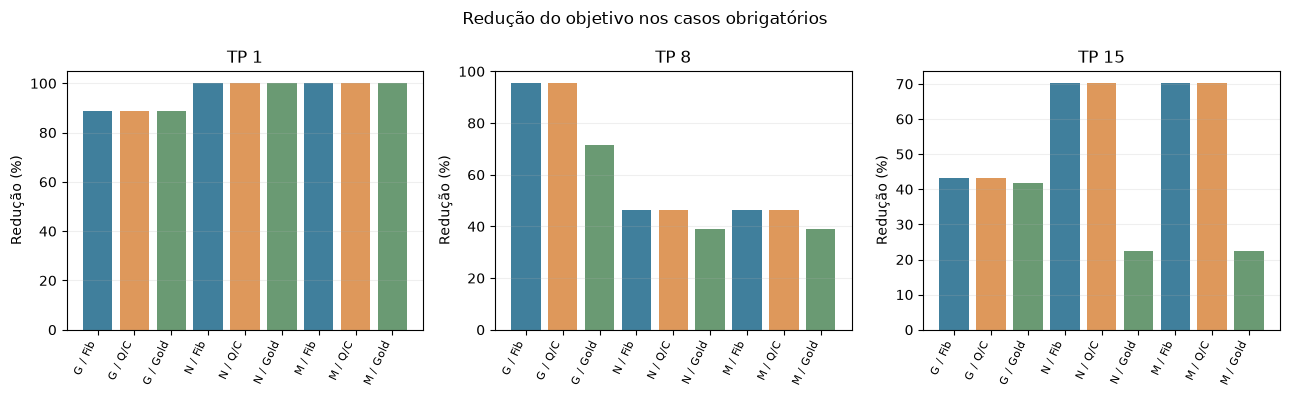

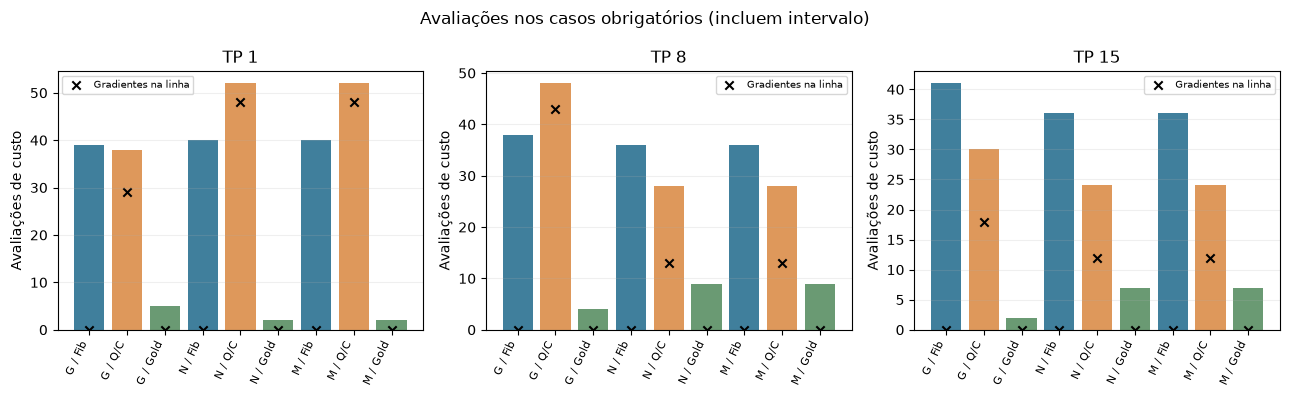

TP 1: 0 casos com substituição N→M; reduções entre 88.7500% e 100.0000%.
TP 8: 3 casos com substituição N→M; reduções entre 38.9877% e 95.3795%.
TP 15: 3 casos com substituição N→M; reduções entre 22.4630% e 70.1609%.
Fibonacci e Q/C aproximam um mínimo da linha sob suas hipóteses; Goldstein aceita redução suficiente.
N e M podem coincidir por mu=0 ou pela substituição exigida; não são trajetórias independentes.


In [12]:
rotulos = [d+" / "+m for d in ("G","N","M") for m in ("Fib","Q/C","Gold")]
for campo,nome_arquivo,titulo,ylabel in (
    ("reducao_percentual","reducoes.png","Redução do objetivo nos casos obrigatórios","Redução (%)"),
    ("avaliacoes_funcao","avaliacoes.png","Avaliações nos casos obrigatórios (incluem intervalo)","Avaliações de custo"),
):
    fig,eixos=plt.subplots(1,3,figsize=(13,4))
    for ax,(nome,p) in zip(eixos,PROBLEMAS.items()):
        linhas=[r for r in obrigatorios if r["problema"]==nome]
        ax.bar(np.arange(9),[r[campo] for r in linhas],color=["#407f9c","#de985b","#6a9a73"]*3)
        if campo=="avaliacoes_funcao":
            ax.scatter(np.arange(9),[r["avaliacoes_gradiente_linha"] for r in linhas],
                       marker="x",color="black",label="Gradientes na linha")
            ax.legend(fontsize=7)
        ax.set_title(nome)
        ax.set_xticks(np.arange(9),rotulos,rotation=65,ha="right",fontsize=8)
        ax.set_ylabel(ylabel)
        ax.grid(axis="y",alpha=.2)
    fig.suptitle(titulo)
    fig.tight_layout()
    fig.savefig(PASTA_SAIDA/nome_arquivo,dpi=150,bbox_inches="tight")
    plt.show()

for nome in PROBLEMAS:
    linhas=[r for r in obrigatorios if r["problema"]==nome]
    substituicoes=[r for r in linhas if r["direcao_solicitada"]=="N" and r["direcao_usada"]=="M"]
    print(f"{nome}: {len(substituicoes)} casos com substituição N→M; "
          f"reduções entre {min(r['reducao_percentual'] for r in linhas):.4f}% e "
          f"{max(r['reducao_percentual'] for r in linhas):.4f}%.")
print("Fibonacci e Q/C aproximam um mínimo da linha sob suas hipóteses; Goldstein aceita redução suficiente.")
print("N e M podem coincidir por mu=0 ou pela substituição exigida; não são trajetórias independentes.")

## 11. Exportação e manual de leitura

`resultados_obrigatorios.csv` tem 27 linhas e inclui os próximos pontos. `resultados_extras.csv` guarda os 27 casos adicionais. `experimentos.json` contém dados completos, históricos, parâmetros, verificações de derivadas e versões. `resumo.md` reúne uma tabela legível. Os PNG mostram reduções e avaliações.

Os valores do CSV/JSON têm maior precisão que as tabelas exibidas. `avaliacoes_funcao` inclui obtenção do intervalo e a avaliação em zero, contando somente custos não presentes no cache. `avaliacoes_gradiente_linha` conta o custo adicional da interpolação cúbica. `iteracoes_intervalo` e `iteracoes_busca` distinguem preparação e busca. O custo inicial das derivadas para formar as direções não está nesses contadores.

Para alterar um teste, modifique `PROBLEMAS` e/ou `PARAMETROS` e execute todas as células. Pontos não diferenciáveis da TP 15 e gradientes nulos exigem diagnóstico, não uma busca forçada. Nenhuma otimização completa ou teste da Parte 1 é reexecutado.

O status `estacionario` distingue um ponto com gradiente numericamente nulo de uma busca concluída com redução. Nesse caso, o registro tem `alfa=0`, `f1=f0`, nenhuma direção aplicada e condições de Goldstein não aplicáveis (`null` no JSON).

In [13]:
def exportar_csv(nome,linhas):
    campos=["tipo","problema","metodo","direcao_solicitada","direcao_usada","diagnostico_direcao",
        "x0_1","x0_2","mu","gTd_original","gTd","alfa","x1_1","x1_2","f0","f1","reducao",
        "reducao_percentual","avaliacoes_funcao","avaliacoes_gradiente_linha","iteracoes_intervalo",
        "iteracoes_busca","status","motivo_parada","goldstein_inferior","goldstein_superior"]
    with (PASTA_SAIDA/nome).open("w",encoding="utf-8-sig",newline="") as arquivo:
        writer=csv.DictWriter(arquivo,fieldnames=campos)
        writer.writeheader()
        for r in linhas:
            linha={campo:r.get(campo) for campo in campos}
            linha.update(x0_1=r["x0"][0],x0_2=r["x0"][1],
                         x1_1=r.get("x1",[None,None])[0],x1_2=r.get("x1",[None,None])[1])
            writer.writerow(linha)

exportar_csv("resultados_obrigatorios.csv",obrigatorios)
exportar_csv("resultados_extras.csv",extras)
documento={"parametros":PARAMETROS,"verificacoes_derivadas":VERIFICACOES,"verificacao_ponto_estacionario":TESTE_ESTACIONARIO,
    "obrigatorios":obrigatorios,"extras":extras,"versoes":{
    "python":platform.python_version(),"numpy":importlib.metadata.version("numpy"),
    "matplotlib":importlib.metadata.version("matplotlib")}}
(PASTA_SAIDA/"experimentos.json").write_text(json.dumps(documento,indent=2,ensure_ascii=False,allow_nan=False),encoding="utf-8")
texto=["# Resultados da Parte 2", "", "27 casos obrigatórios e 27 extras; um passo por caso.", "",
       "N/M indica Newton solicitado e modificado aplicado. A revisão final identificou e corrigiu o registro de pontos estacionários; consulte auditoria critica de erros.md.", ""]
for titulo,linhas in (("Casos obrigatórios",obrigatorios),("Testes extras",extras)):
    texto += ["## "+titulo,"", "| TP | Sol./usada | Método | μ | α | Próximo ponto | f0 | f1 | Redução % | f/grad |",
              "|---|---|---|---:|---:|---|---:|---:|---:|---:|"]
    for r in linhas:
        texto.append(f"| {r['problema']} | {r['direcao_solicitada']}/{r['direcao_usada']} | {r['metodo']} | "
            f"{r['mu']:.8g} | {r['alfa']:.10g} | ({r['x1'][0]:.9g}, {r['x1'][1]:.9g}) | "
            f"{r['f0']:.10g} | {r['f1']:.10g} | {r['reducao_percentual']:.6f} | "
            f"{r['avaliacoes_funcao']}/{r['avaliacoes_gradiente_linha']} |")
    texto.append("")
(PASTA_SAIDA/"resumo.md").write_text(chr(10).join(texto),encoding="utf-8")
print("Arquivos exportados:")
for arquivo in sorted(PASTA_SAIDA.iterdir()):
    print(" -",arquivo.name)
print("Parte 2 executada; revisão final e auditoria crítica registradas.")

Arquivos exportados:
 - avaliacoes.png
 - experimentos.json
 - reducoes.png
 - resultados_extras.csv
 - resultados_obrigatorios.csv
 - resumo.md
Parte 2 executada; revisão final e auditoria crítica registradas.
